# Labels: the logit identity and the budget's boundary

Verification notebook. Checks: the row-wise forms equal the scalar forms (VB.2); the label-noise identity and per-arm radii (V7.1); the closed-form path along the $e_k$-$u$ line (V7.2); the derivative sign behind the adversary's position (V7.3); the exact collapse threshold (V7.4); and the sweep's statements (V7.5). The sweep figure is drawn from the frozen 16-seed sweep in `noise_sweep.json` (`python -m lrd.noise_sweep`, about two hours).

In [1]:
from lrd.checks import labels
from lrd import paths
import numpy as np
import matplotlib.pyplot as plt
from lrd import noise_sweep

## VB.2 — the row-wise forms equal the scalar forms

The training code uses `D_rows` / `subgrad_rows`, vectorised over rows; they must equal the scalar `D` / `subgrad` used everywhere else. This is the assertion that stops the training code and the solver code from drifting apart.

In [2]:
labels.vb_2()

PASS  VB.2: row-wise forms equal the scalar forms
  => max|D_rows - D| = 2.33e-10;  max|subgrad_rows - subgrad| = 1.11e-16

## V7.1 — the label-noise identity, and per-arm radii

Symmetric label noise at rate $\rho$ gives $\hat p = (1-\lambda)p + \lambda u$ with $\lambda = n\rho/(n-1)$, an exact identity. The displacement $\lambda\lVert u - e_k\rVert_{r^*}$ differs across members, so a single radius cannot serve all three.

In [3]:
labels.v7_1()

PASS  V7.1: the label-noise identity, per-arm radii  [thm:neg]
    rho=0.1:  radii (r=1,2,inf) = 0.1000  0.1054  0.2000
    rho=0.2:  radii (r=1,2,inf) = 0.2000  0.2108  0.4000
    rho=0.4:  radii (r=1,2,inf) = 0.4000  0.4216  0.8000
  => max identity residual = 1.1e-16

## V7.2 — the path lies on the $e_k$-$u$ line

With nominal $(1-\lambda)e_k + \lambda u$, the robust solution is $(1-\mu)e_k + \mu u$ with $\mu = \min(1, \lambda + \varepsilon/\lVert u - e_k\rVert_{r^*})$. We check the solver against this closed form, including past saturation.

In [4]:
labels.v7_2()

PASS  V7.2: the closed-form path on the e_k-u line  [thm:neg]
  => max|solver - closed form| = 2.43e-09 over (n, rho) x 3 members x 4 radii; one-hot nominal (lam = 0): 3.16e-09 over n in {3, 5, 10} x 5 members x 6 radii

## V7.3 — the derivative sign (where the adversary sits)

The worst case is at the uniform end because expected log-loss increases along the $e_k$-$u$ ray once the model puts above-average mass on the true class. The sign identity holds, and we report the fraction where the precondition fails.

In [5]:
labels.v7_3()

PASS  V7.3: the derivative sign (where the adversary sits)  [thm:neg]
  => sign disagreements 0/4000; precondition fails on 49.4% of random x

## V7.4 — collapse: past an exact threshold the minimiser is $W = 0$

The objective is convex in $W$, so $W=0$ is optimal exactly when the cross-entropy gradient at the origin lies in $\varepsilon$ times the penalty's subdifferential there; the threshold $\varepsilon_c$ is a linear programme at $r\in\{1,\infty\}$ and a convex programme at $r=2$. Past it the model predicts the uniform distribution. Started at $W=0$ the optimiser also stops there for $\varepsilon$ in $[\varepsilon_G,\varepsilon_c)$; warm-started just below $\varepsilon_c$ it does not. Slow: a few minutes.

In [6]:
labels.v7_4()

PASS  V7.4: collapse: past an exact threshold the minimiser is W = 0  [obs:collapse]
    r=  1: eps_c = 0.1858 (exact), eps_G = 0.1377;  |W|max at 0.9 eps_G = 1.8e-01; inside [eps_G, eps_c) from 0: 0.0e+00, at 0.97 eps_c warm-started: 2.1e-02;  at 0.20: |W|max 2e-13, cos(W, descent) 1.0000000;  at 3.00: |W|max 1e-13, cos(W, descent) 1.0000000
    r=  2: eps_c = 0.3649 (exact), eps_G = 0.3435;  |W|max at 0.9 eps_G = 1.0e-01; inside [eps_G, eps_c) from 0: 0.0e+00, at 0.97 eps_c warm-started: 2.1e-02;  at 0.40: W = 0 exactly;  at 3.00: |W|max 1e-13, cos(W, descent) 1.0000000
    r=inf: eps_c = 0.7005 (exact), eps_G = 0.6420;  |W|max at 0.9 eps_G = 1.1e-01; inside [eps_G, eps_c) from 0: 0.0e+00, at 0.97 eps_c warm-started: 2.0e-02;  at 0.77: W = 0 exactly;  at 3.00: |W|max 1e-13, cos(W, descent) 1.0000000
    argmax of the residue: accuracy 0.5910-0.5910; prototype rule <x, mu_k>: 0.6092
  => past eps_c the minimiser is W = 0 (uniform predictions); the reported "plateau" 0.59 is the argmax

## V7.5 — the sweep: capacity control, not a certificate

Read from the frozen 16-seed sweep (`noise_sweep.json`). Each arm's strength is chosen on a noisy validation set and scored on clean held-out data; arms are compared with 95% intervals paired by seed. Checks the statements of the sweep section: the penalty helps at $\rho=0$; its best strength does not track the noise; label smoothing is within noise of the best $D_r$ arm or above it; every $D_r$ arm collapses by $\varepsilon=1.2$; every chosen strength is inside its grid; the prototype rule is within noise of the best arm at $\rho=0$ and above it at $\rho>0$.

In [7]:
labels.v7_5()

PASS  V7.5: the sweep: capacity control, not a certificate  [fig:sweep]
    16 seeds; test accuracy at the validation choice, and difference from the best arm [95% paired interval]:
    rho=0.0: unpenalised 0.6908;  D_1 0.7071 (-0.0011 [-0.0020, -0.0001]);  D_2 0.7082 (+0.0000 [+0.0000, +0.0000]);  D_inf 0.7063 (-0.0019 [-0.0032, -0.0006]);  ls 0.7072 (-0.0009 [-0.0019, +0.0001]);  cp 0.7058 (-0.0023 [-0.0032, -0.0014]);  prototype 0.7058 (-0.0024 [-0.0108, +0.0060])
      gain over unpenalised at rho = 0 (points): D_1 +1.63 [+1.26, +2.00];  D_2 +1.74 [+1.38, +2.10];  D_inf +1.55 [+1.22, +1.87];  ls +1.65 [+1.23, +2.06];  cp +1.50 [+1.13, +1.88]
      members, paired: D_2 - D_1 +0.11 [+0.01, +0.20];  D_2 - D_inf +0.19 [+0.06, +0.32];  D_inf - D_1 -0.08 [-0.23, +0.06]
    rho=0.1: unpenalised 0.6519;  D_1 0.6791 (-0.0043 [-0.0053, -0.0033]);  D_2 0.6815 (-0.0019 [-0.0028, -0.0009]);  D_inf 0.6782 (-0.0052 [-0.0072, -0.0032]);  ls 0.6834 (+0.0000 [+0.0000, +0.0000]);  cp 0.6827 (-0.0007 

## The sweep figure

Held-out accuracy against penalty strength, one column per noise rate, one-hot nominal, 95% intervals over seeds. Top: the $D_r$ arms against $\varepsilon/\varepsilon_c$ ($\varepsilon_c$ the smallest exact threshold over seeds). Middle and bottom: label smoothing and the confidence penalty against their own weights. Grey: unpenalised; dashed: the prototype rule $\langle x,\mu_k\rangle$.

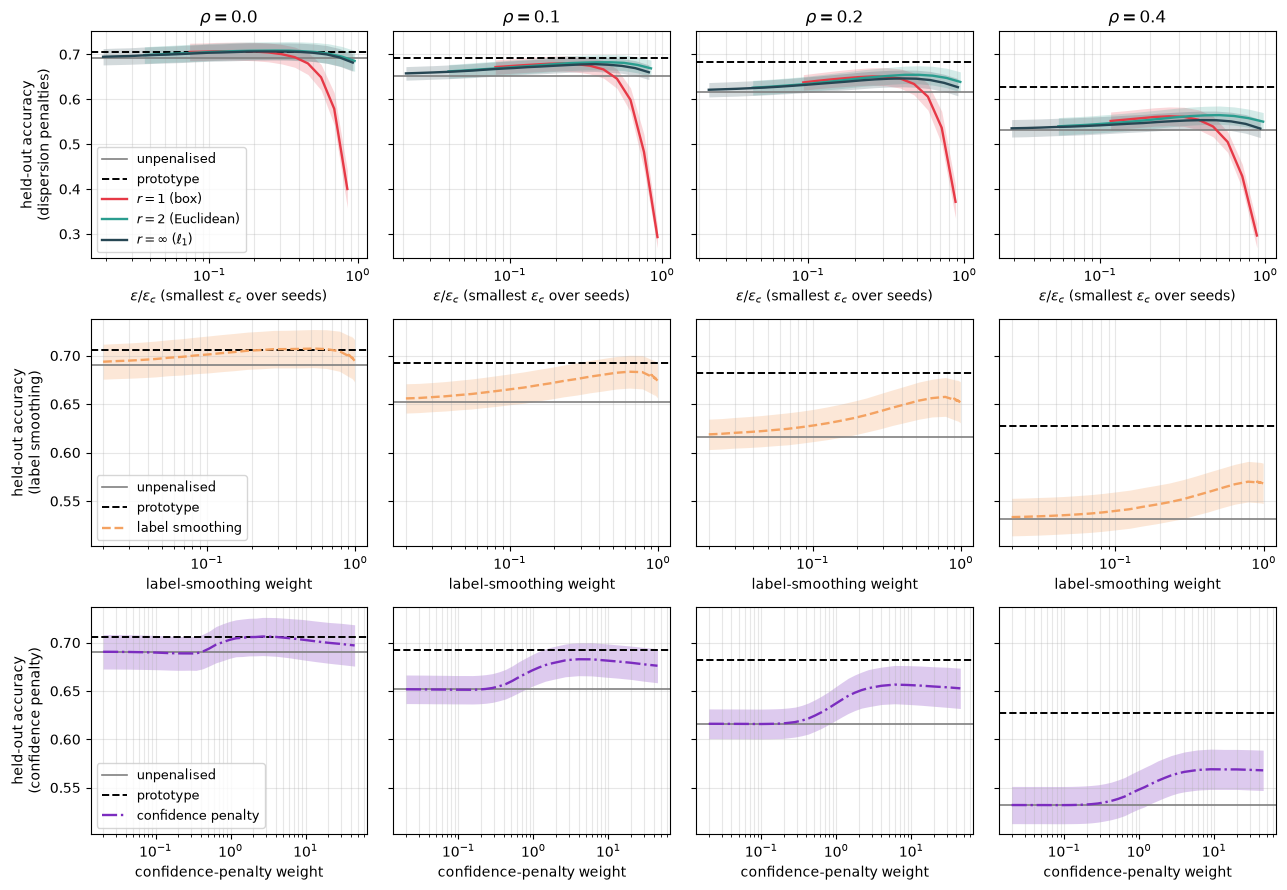

In [8]:
sw = noise_sweep.load_sweep()
rhos = [0.0, 0.1, 0.2, 0.4]
D = [('D_1', '#e63946', r'$r=1$ (box)'), ('D_2', '#2a9d8f', r'$r=2$ (Euclidean)'),
     ('D_inf', '#264653', r'$r=\infty$ ($\ell_1$)')]
T95 = 2.131                                   # t quantile, 15 degrees of freedom (16 seeds)


def mean_ci(A):
    m = A.mean(0); se = A.std(0, ddof=1) / np.sqrt(A.shape[0])
    return m, m - T95 * se, m + T95 * se


fig, axes = plt.subplots(3, 4, figsize=(13, 9), sharey='row')
for j, rho in enumerate(rhos):
    R = sw['res'][f'onehot|{rho}']
    A0 = np.array(R['D_1']['per_seed'], float)[:, 0]          # s = 0: the unpenalised model
    for i in range(3):
        ax = axes[i, j]
        ax.axhline(A0.mean(), color='gray', lw=1.2, label='unpenalised')
        ax.axhline(R['prototype']['best'], color='black', ls='--', lw=1.4, label='prototype')
    ax = axes[0, j]
    for name, col, lab in D:
        o = R[name]; g = np.array(o['grid']); A = np.array(o['per_seed'], float)
        live = (np.array(o['collapsed_frac']) == 0) & (g > 0)
        x = g / min(o['eps_c'])
        m, lo, hi = mean_ci(A[:, live])
        ax.semilogx(x[live], m, color=col, lw=1.7, label=lab)
        ax.fill_between(x[live], lo, hi, color=col, alpha=.2, lw=0)
    ax.set_xlabel(r'$\varepsilon / \varepsilon_c$ (smallest $\varepsilon_c$ over seeds)')
    for i, (name, col, lsty, xl) in enumerate([('ls', '#f4a261', '--', 'label-smoothing weight'),
                                         ('cp', '#7b2cbf', '-.', 'confidence-penalty weight')], start=1):
        ax = axes[i, j]; o = R[name]; g = np.array(o['grid']); A = np.array(o['per_seed'], float)
        live = g > 0
        m, lo, hi = mean_ci(A[:, live])
        ax.semilogx(g[live], m, color=col, ls=lsty, lw=1.7,
                    label={'ls': 'label smoothing', 'cp': 'confidence penalty'}[name])
        ax.fill_between(g[live], lo, hi, color=col, alpha=.25, lw=0)
        ax.set_xlabel(xl)
    axes[0, j].set_title(f'$\\rho = {rho}$')
for i, lab in enumerate(['dispersion penalties', 'label smoothing', 'confidence penalty']):
    axes[i, 0].set_ylabel(f'held-out accuracy\n({lab})')
    for ax in axes[i]:
        ax.grid(alpha=.3, which='both')
    axes[i, 0].legend(fontsize=9, loc='lower left')
fig.tight_layout(); fig.savefig(paths.figure('fig_sweep.pdf'), bbox_inches='tight')
plt.show()

## fig:paths — four paths from one nominal (§7.2)
Members ($r=\infty$, $r=2$) and relatives (label smoothing, confidence penalty) leave $\hat p=(0.7,0.22,0.08)$ in different directions; check V3.8 quantifies the split.

saved fig_paths.pdf


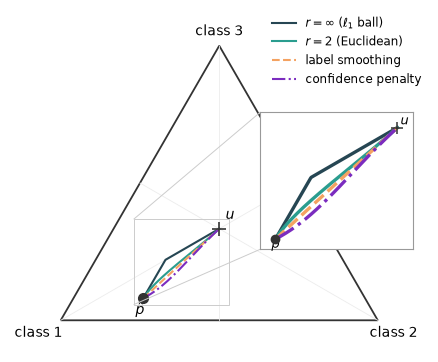

In [9]:
import numpy as np, matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from scipy.optimize import minimize
from scipy.special import logsumexp
from lrd.solver import solve as solve_r
from lrd.core import nrm, dual
from lrd.paths import figure as figpath

V=np.array([[0,0],[1,0],[0.5,np.sqrt(3)/2]],float); to_cart=lambda p: np.asarray(p)@V
ph=np.array([0.7,0.22,0.08]); u=np.ones(3)/3
STY=[('#264653','-',r'$r=\infty$ ($\ell_1$ ball)'),('#2a9d8f','-',r'$r=2$ (Euclidean)'),
     ('#f4a261','--','label smoothing'),('#7b2cbf','-.','confidence penalty')]
def path_r(r): esat=nrm(ph-u,dual(r)); return np.array([solve_r(ph,float(e),r) for e in np.linspace(0,esat*0.999,160)])
path_ls=lambda: np.array([(1-a)*ph+a*u for a in np.linspace(0,1,160)])
def path_cp():
    out=[ph]
    for b in np.geomspace(1e-3,80,160):
        F=lambda z:(lambda z:-ph@np.log(np.exp(z-logsumexp(z)))+b*np.sum(np.exp(z-logsumexp(z))*(z-logsumexp(z))))(z-z.mean())
        r=minimize(F,np.zeros(3),method='Nelder-Mead',options=dict(xatol=1e-11,fatol=1e-13,maxiter=30000))
        z=r.x-r.x.mean(); out.append(np.exp(z-logsumexp(z)))
    return np.array(out)
P=[path_r(np.inf),path_r(2.0),path_ls(),path_cp()]
def draw_simplex(ax):
    ax.add_patch(plt.Polygon(V,fill=False,edgecolor='#333',lw=1.3))
    for (ox,oy),lab in zip([(-.07,-.04),(1.05,-.04),(.5,np.sqrt(3)/2+.045)],['class 1','class 2','class 3']):
        ax.text(ox,oy,lab,ha='center',va='center',fontsize=10)
    uu=to_cart(u); mids=(V+np.roll(V,-1,axis=0))/2
    for v in np.vstack([V,mids]): ax.plot([uu[0],v[0]],[uu[1],v[1]],color='#ececec',lw=.6,zorder=1)
    ax.plot(*uu,'+',color='#333',ms=10,mew=1.2,zorder=5); ax.text(uu[0]+.02,uu[1]+.03,'$u$',fontsize=10)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_xlim(-.16,1.16); ax.set_ylim(-.10,.98)
fig,ax=plt.subplots(figsize=(5.4,4.8)); draw_simplex(ax)
for X,(col,ls,lab) in zip(P,STY): ax.plot(*to_cart(X).T,color=col,lw=1.5,ls=ls,label=lab,zorder=4)
ax.plot(*to_cart(ph),'o',color='#333',ms=7,zorder=7); ax.text(to_cart(ph)[0]-.01,to_cart(ph)[1]-.05,r'$\hat p$',ha='center',fontsize=10)
ax.legend(loc='upper right',fontsize=8.5,frameon=False,borderaxespad=0.2)
axi=ax.inset_axes([0.58,0.30,0.40,0.40]); axi.set_facecolor('white'); axi.set_zorder(9)
for X,(col,ls,lab) in zip(P,STY): axi.plot(*to_cart(X).T,color=col,lw=2.4,ls=ls,zorder=4)
axi.plot(*to_cart(ph),'o',color='#333',ms=6,zorder=7); axi.text(to_cart(ph)[0],to_cart(ph)[1]-.018,r'$\hat p$',ha='center',fontsize=9)
axi.plot(*to_cart(u),'+',color='#333',ms=8,mew=1.1,zorder=5); axi.text(to_cart(u)[0]+.006,to_cart(u)[1]+.006,'$u$',fontsize=9)
pc,uc=to_cart(ph),to_cart(u)
axi.set_xlim(min(pc[0],uc[0])-.03,max(pc[0],uc[0])+.03); axi.set_ylim(min(pc[1],uc[1])-.02,max(pc[1],uc[1])+.03)
axi.set_aspect('equal'); axi.set_xticks([]); axi.set_yticks([])
for s in axi.spines.values(): s.set_edgecolor('#999'); s.set_linewidth(.8)
mark_inset(ax,axi,loc1=2,loc2=3,fc='none',ec='#cccccc',lw=.7)
fig.savefig(figpath('fig_paths.pdf'),bbox_inches='tight'); print('saved fig_paths.pdf')